# Notebook 3 - Huấn luyện và đánh giá mô hình Hồi quy Logistic (Bước 6)

Notebook này xây dựng mô hình máy học đầu tiên: **Hồi quy logistic** (Logistic Regression) trên bộ 153 đặc trưng đã được tiền xử lý và mã hóa từ Notebook 2.

Quy trình thực hiện gồm 4 phần chính:
1. **Nạp dữ liệu:** Nạp tập train, val và thông tin đặc trưng.
2. **Huấn luyện mô hình:** Fit mô hình Logistic Regression trên tập train.
3. **Hệ thống các metric đánh giá mô hình:** Đầy đủ các thước đo xếp hạng tín dụng (ROC-AUC, Gini, PR-AUC, KS Statistic), thước đo xác suất (Brier Score, Log-Loss), kiểm tra quá khớp (Overfitting) và các thước đo phân loại theo ngưỡng quyết định (Accuracy, Precision, Recall, F1, Confusion Matrix).
4. **Phân tích hệ số:** Khám phá các đặc trưng tài chính tác động mạnh nhất đến rủi ro vỡ nợ.

**Quy tắc làm việc:** fit trên tập `train`, đánh giá trên tập `val`. **Tập `test` chưa được mở**. Mỗi hàm, mỗi kết quả một ô code.

In [1]:
from pathlib import Path
import json
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
    brier_score_loss, log_loss, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)

In [2]:
SEED = 42
ROOT = Path("..")
DATA_DIR = ROOT / "data/processed"
ART_DIR = ROOT / "artifacts"
FIG_DIR = ART_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.4f}".format)

## 1. Nạp dữ liệu
Nạp dữ liệu đã xử lý từ Notebook 2: `X_train.npy`, `y_train.npy`, `X_val.npy`, `y_val.npy` và danh sách tên các đặc trưng `feature_names.json`.

In [3]:
feature_info = json.loads((DATA_DIR / "feature_names.json").read_text())
feature_names = feature_info["feature_names"]
numeric_cols = feature_info["numeric"]
categorical_cols = feature_info["categorical"]
print(f"Tổng số feature sau tiền xử lý: {len(feature_names)} ({len(numeric_cols)} cột số, {len(categorical_cols)} cột phân loại gốc)")

Tổng số feature sau tiền xử lý: 153 (45 cột số, 5 cột phân loại gốc)


In [4]:
X_train = np.load(DATA_DIR / "X_train.npy")
y_train = np.load(DATA_DIR / "y_train.npy")
X_val = np.load(DATA_DIR / "X_val.npy")
y_val = np.load(DATA_DIR / "y_val.npy")
print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_val:   {X_val.shape}, y_val:   {y_val.shape}")
print(f"Tỷ lệ nhãn vỡ nợ (default=1): train {y_train.mean():.4f}, val {y_val.mean():.4f}")

X_train: (464185, 153), y_train: (464185,)
X_val:   (95405, 153), y_val:   (95405,)
Tỷ lệ nhãn vỡ nợ (default=1): train 0.1483, val 0.1481


---
## 2. Huấn luyện mô hình Hồi quy Logistic
Hồi quy logistic dự đoán xác suất vỡ nợ thông qua hàm sigmoid:
$$P(y=1) = \frac{1}{1 + e^{-(w^T x + b)}}$$

Mô hình được huấn luyện trên tập `train`. Cột số đã được chuẩn hóa qua `StandardScaler` ở Notebook 2 nên các hệ số trọng số có thể so sánh độ lớn trực tiếp với nhau.

In [5]:
def fit_logistic(X_train, y_train):
    model = LogisticRegression(max_iter=1000, random_state=SEED)
    return model.fit(X_train, y_train)

In [6]:
t0 = time.time()
model = fit_logistic(X_train, y_train)
print(f"Hồi quy logistic: fit xong sau {time.time() - t0:.1f}s, hội tụ sau {model.n_iter_[0]} vòng lặp.")

Hồi quy logistic: fit xong sau 7.0s, hội tụ sau 77 vòng lặp.


In [7]:
train_score = model.predict_proba(X_train)[:, 1]
val_score = model.predict_proba(X_val)[:, 1]
print("Đã tính xác suất vỡ nợ dự đoán (predicted probability) trên tập train và val.")

Đã tính xác suất vỡ nợ dự đoán (predicted probability) trên tập train và val.


---
## 3. Hệ thống các metric đánh giá mô hình

Để đánh giá toàn diện mô hình chấm điểm tín dụng trong điều kiện mất cân bằng lớp (tỷ lệ vỡ nợ ~14.8%), ta chia hệ thống metric thành 3 nhóm:
1. **Nhóm xếp hạng rủi ro tín dụng (Ranking / Discrimination):** ROC-AUC, Gini, PR-AUC, KS Statistic (độc lập với ngưỡng quyết định).
2. **Nhóm đo độ chuẩn xác của xác suất (Probability Calibration & Loss):** Brier Score, Log-Loss.
3. **Nhóm phân loại theo ngưỡng quyết định (Threshold-based Metrics):** Accuracy, Precision, Recall, Specificity, F1-Score, Confusion Matrix.

### 3.1 Thước đo xếp hạng tín dụng và chất lượng xác suất

| Metric | Ý nghĩa tín dụng / thống kê | Mức chuẩn mong đợi |
|---|---|---|
| **ROC-AUC** | Khả năng xếp hạng rủi ro: xác suất chọn ngẫu nhiên 1 khoản vỡ nợ được điểm rủi ro cao hơn khoản trả đủ | 0.5 (đoán mò) -> 1.0 (hoàn hảo) |
| **Gini** ($2 \times \text{AUC} - 1$) | Thước đo tiêu chuẩn ngành ngân hàng/tín dụng để đo độ phân tách rủi ro | > 30% là khả quan, > 40% là tốt |
| **PR-AUC** | Diện tích dưới đường Precision-Recall: đo khả năng bắt lớp thiểu số vỡ nợ | Càng cao hơn tỷ lệ vỡ nợ nền (~0.148) càng tốt |
| **KS Statistic** ($\max(\text{TPR} - \text{FPR})$) | Khoảng cách phân tách lớn nhất giữa phân phối người vay tốt và xấu | 20% - 40% là mô hình tín dụng tốt |
| **Brier Score** | Sai số bình phương trung bình giữa xác suất dự đoán và nhãn thực tế | Càng gần 0 càng tốt |
| **Log-Loss** | Hàm mất mát binary cross-entropy: phạt nặng các dự đoán sai với độ tự tin cao | Càng thấp càng tốt |

In [8]:
def evaluate_rank_and_prob(y_true, score):
    fpr, tpr, _ = roc_curve(y_true, score)
    roc_auc = roc_auc_score(y_true, score)
    gini = 2 * roc_auc - 1
    pr_auc = average_precision_score(y_true, score)
    ks_stat = np.max(tpr - fpr)
    brier = brier_score_loss(y_true, score)
    logloss = log_loss(y_true, score)
    return {
        "ROC-AUC": roc_auc,
        "Gini": gini,
        "PR-AUC": pr_auc,
        "KS Statistic": ks_stat,
        "Brier Score": brier,
        "Log-Loss": logloss,
    }

In [9]:
val_metrics = pd.DataFrame([evaluate_rank_and_prob(y_val, val_score)], index=["Hồi quy logistic"]).T
val_metrics.columns = ["Giá trị trên Val"]
val_metrics

Out[0]: 
              Giá trị trên Val
ROC-AUC                 0.7010
Gini                    0.4021
PR-AUC                  0.2754
KS Statistic            0.2950
Brier Score             0.1182
Log-Loss                0.3874


,Giá trị trên Val
ROC-AUC,0.7010
Gini,0.4021
PR-AUC,0.2754
KS Statistic,0.2950
Brier Score,0.1182
Log-Loss,0.3874


In [10]:
print("Nhận xét về các thước đo tín dụng trên tập Validation:")
print(f"- ROC-AUC đạt {val_metrics.loc['ROC-AUC', 'Giá trị trên Val']:.4f} tương ứng Gini đạt {val_metrics.loc['Gini', 'Giá trị trên Val']:.1%}.")
print(f"- KS Statistic đạt {val_metrics.loc['KS Statistic', 'Giá trị trên Val']:.1%}: nằm trong khoảng phân tách tốt (25% - 40%) theo chuẩn thẩm định rủi ro tín dụng.")
print(f"- PR-AUC đạt {val_metrics.loc['PR-AUC', 'Giá trị trên Val']:.4f}, cao gần gấp đôi tỷ lệ vỡ nợ ngẫu nhiên ({y_val.mean():.4f}).")

Nhận xét về các thước đo tín dụng trên tập Validation:
- ROC-AUC đạt 0.7010 tương ứng Gini đạt 40.2%.
- KS Statistic đạt 29.5%: nằm trong khoảng phân tách tốt (25% - 40%) theo chuẩn thẩm định rủi ro tín dụng.
- PR-AUC đạt 0.2754, cao gần gấp đôi tỷ lệ vỡ nợ ngẫu nhiên (0.1481).


### 3.2 Kiểm tra hiện tượng quá khớp (Overfitting Check)
So sánh các chỉ số giữa tập huấn luyện (`train`) và tập kiểm định (`val`).

In [11]:
train_m = evaluate_rank_and_prob(y_train, train_score)
val_m = evaluate_rank_and_prob(y_val, val_score)

overfit_df = pd.DataFrame({"train": train_m, "val": val_m})
overfit_df["train - val"] = overfit_df["train"] - overfit_df["val"]
overfit_df

Out[0]: 
              train    val  train - val
ROC-AUC      0.6945 0.7010      -0.0065
Gini         0.3891 0.4021      -0.0130
PR-AUC       0.2756 0.2754       0.0002
KS Statistic 0.2830 0.2950      -0.0120
Brier Score  0.1184 0.1182       0.0002
Log-Loss     0.3889 0.3874       0.0015


,train,val,train - val
ROC-AUC,0.6945,0.7010,-0.0065
Gini,0.3891,0.4021,-0.0130
PR-AUC,0.2756,0.2754,0.0002
KS Statistic,0.2830,0.2950,-0.0120
Brier Score,0.1184,0.1182,0.0002
Log-Loss,0.3889,0.3874,0.0015


In [12]:
diff_auc = overfit_df.loc['ROC-AUC', 'train - val']
direction = "cao hơn" if diff_auc > 0 else "thấp hơn"
print(f"ROC-AUC train {direction} ROC-AUC val: {abs(diff_auc):.4f}.")
print("Độ lệch rất nhỏ và âm giữa train và val khẳng định mô hình không bị quá khớp (no overfitting).")

ROC-AUC train thấp hơn ROC-AUC val: 0.0065.
Độ lệch rất nhỏ và âm giữa train và val khẳng định mô hình không bị quá khớp (no overfitting).


### 3.3 Thước đo phân loại theo ngưỡng quyết định (Threshold-based Metrics) & Ma trận nhầm lẫn

Để ra quyết định cho vay / từ chối, ta cần chọn một **ngưỡng xác suất** ($P_{th}$):
- Nếu $P(\text{vỡ nợ}) \ge P_{th} \to$ Dự báo vỡ nợ (từ chối vay).
- Nếu $P(\text{vỡ nợ}) < P_{th} \to$ Dự báo trả đủ (duyệt vay).

Dưới đây ta so sánh hai ngưỡng quan trọng:
1. **Ngưỡng mặc định 0.5:** Ngưỡng chuẩn của scikit-learn. Với dữ liệu mất cân bằng (chỉ 14.8% nợ xấu), ngưỡng này quá cao khiến mô hình hầu như không bắt được khoản nợ xấu nào.
2. **Ngưỡng theo tỷ lệ nợ xấu thực tế (~0.148):** Phù hợp với bài toán quản trị rủi ro tín dụng thực tế.

In [13]:
def evaluate_threshold(y_true, score, threshold):
    y_pred = (score >= threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    spec = tn / (tn + fp)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    return {
        "Ngưỡng": threshold,
        "Accuracy": acc,
        "Precision": prec,
        "Recall (Độ nhạy)": rec,
        "Specificity (Độ đặc hiệu)": spec,
        "F1-Score": f1,
        "TP (Bắt đúng nợ xấu)": tp,
        "FP (Cảnh báo nhầm)": fp,
        "FN (Bỏ lọt nợ xấu)": fn,
        "TN (Duyệt đúng người tốt)": tn,
    }

In [14]:
prior_threshold = float(y_train.mean())
threshold_results = pd.DataFrame([
    evaluate_threshold(y_val, val_score, threshold=0.50),
    evaluate_threshold(y_val, val_score, threshold=prior_threshold),
]).set_index("Ngưỡng")
threshold_results

Out[0]: 
        Accuracy  Precision  ...  FN (Bỏ lọt nợ xấu)  TN (Duyệt đúng người tốt)
Ngưỡng                       ...                                               
0.5000    0.8519     0.4842  ...               14084                      81226
0.1483    0.6569     0.2446  ...                5225                      53771

[2 rows x 9 columns]


,Accuracy,Precision,Recall (Độ nhạy),Specificity (Độ đặc hiệu),F1-Score,TP (Bắt đúng nợ xấu),FP (Cảnh báo nhầm),FN (Bỏ lọt nợ xấu),TN (Duyệt đúng người tốt)
Ngưỡng,,,,,,,,,
0.5000,0.8519,0.4842,0.0033,0.9994,0.0065,46,49,14084,81226
0.1483,0.6569,0.2446,0.6302,0.6616,0.3524,8905,27504,5225,53771


In [15]:
rec_prior = threshold_results.loc[prior_threshold, 'Recall (Độ nhạy)']
prec_prior = threshold_results.loc[prior_threshold, 'Precision']
tp_prior = int(threshold_results.loc[prior_threshold, 'TP (Bắt đúng nợ xấu)'])
fn_prior = int(threshold_results.loc[prior_threshold, 'FN (Bỏ lọt nợ xấu)'])
print(f"So sánh hai ngưỡng quyết định:")
print(f"1. Ở ngưỡng 0.5: Accuracy cao ({threshold_results.loc[0.5, 'Accuracy']:.1%}) nhưng Recall chỉ đạt {threshold_results.loc[0.5, 'Recall (Độ nhạy)']:.1%}, bỏ lọt hầu hết các khoản nợ xấu.")
print(f"2. Ở ngưỡng {prior_threshold:.4f} (theo tỷ lệ nợ xấu nền): Recall tăng vọt lên {rec_prior:.1%}, bắt được {tp_prior:,} / {tp_prior + fn_prior:,} khoản vỡ nợ với Precision đạt {prec_prior:.1%}.")

So sánh hai ngưỡng quyết định:
1. Ở ngưỡng 0.5: Accuracy cao (85.2%) nhưng Recall chỉ đạt 0.3%, bỏ lọt hầu hết các khoản nợ xấu.
2. Ở ngưỡng 0.1483 (theo tỷ lệ nợ xấu nền): Recall tăng vọt lên 63.0%, bắt được 8,905 / 14,130 khoản vỡ nợ với Precision đạt 24.5%.


### 3.4 Biểu đồ ROC Curve và Precision-Recall Curve
Trực quan hóa sự đánh đổi giữa các tỷ lệ phân loại.

<ipython-input-1-62d9c5dcc1c2>:26: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


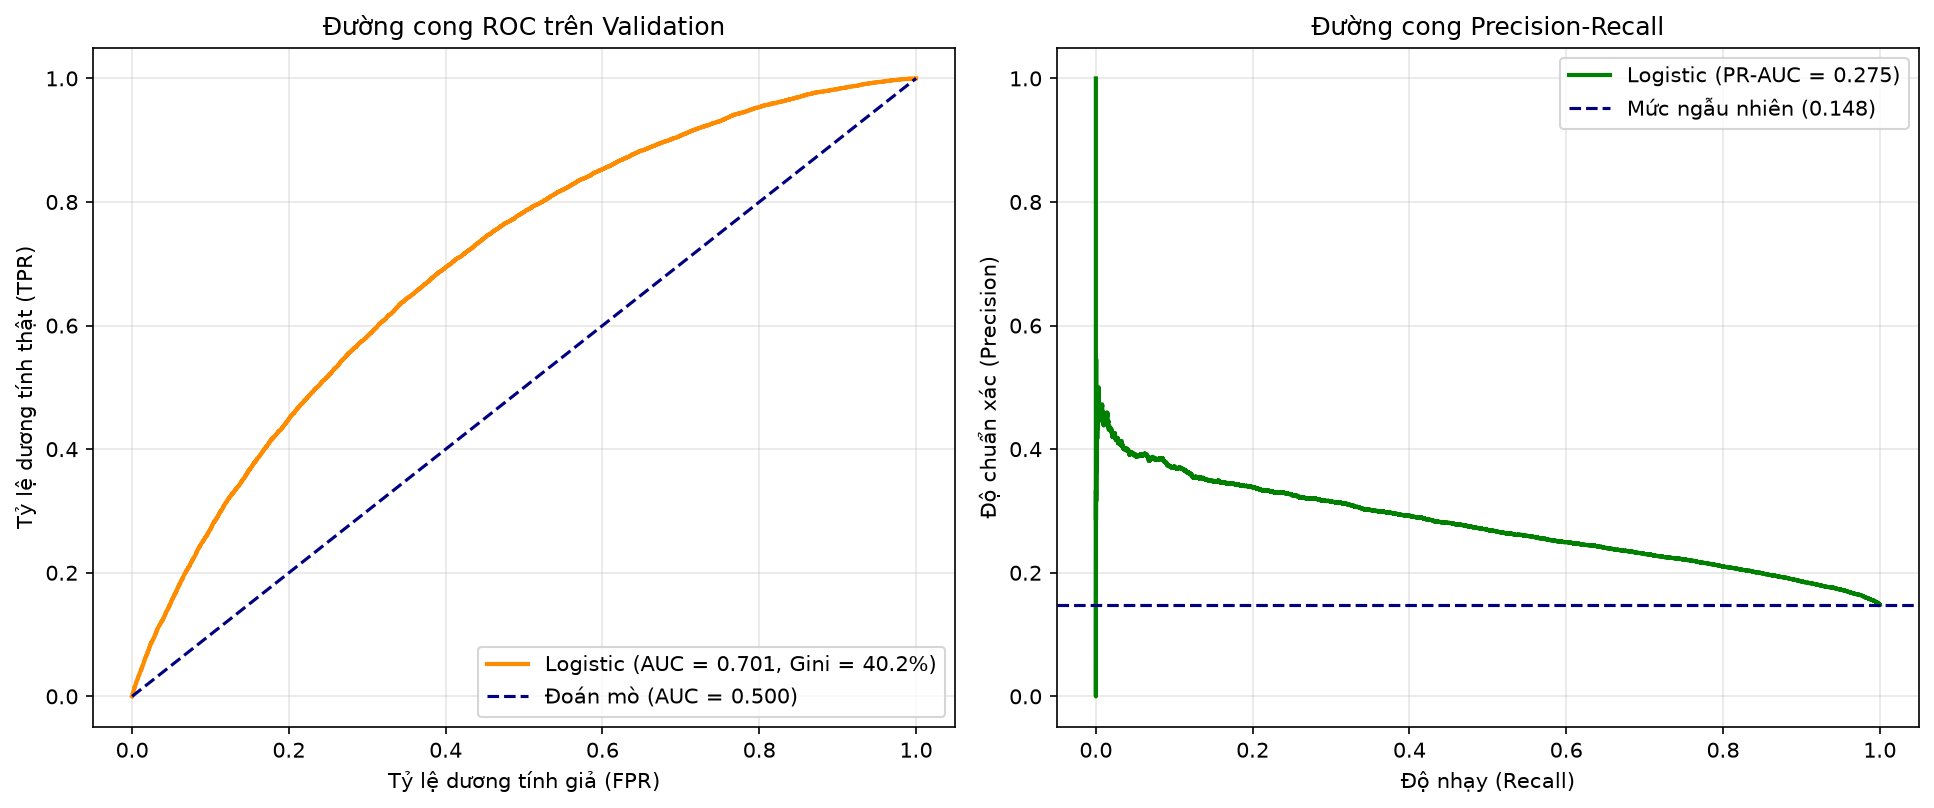

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# 1. Đường cong ROC
fpr, tpr, _ = roc_curve(y_val, val_score)
axes[0].plot(fpr, tpr, color='darkorange', lw=2, label=f"Logistic (AUC = {val_m['ROC-AUC']:.3f}, Gini = {val_m['Gini']:.1%})")
axes[0].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label="Đoán mò (AUC = 0.500)")
axes[0].set_xlabel("Tỷ lệ dương tính giả (FPR)")
axes[0].set_ylabel("Tỷ lệ dương tính thật (TPR)")
axes[0].set_title("Đường cong ROC trên Validation")
axes[0].legend(loc="lower right")
axes[0].grid(True, alpha=0.3)

# 2. Đường cong Precision-Recall
prec_curve, rec_curve, _ = precision_recall_curve(y_val, val_score)
axes[1].plot(rec_curve, prec_curve, color='green', lw=2, label=f"Logistic (PR-AUC = {val_m['PR-AUC']:.3f})")
axes[1].axhline(y=y_val.mean(), color='navy', linestyle='--', label=f"Mức ngẫu nhiên ({y_val.mean():.3f})")
axes[1].set_xlabel("Độ nhạy (Recall)")
axes[1].set_ylabel("Độ chuẩn xác (Precision)")
axes[1].set_title("Đường cong Precision-Recall")
axes[1].legend(loc="upper right")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / "02_roc_logistic_val.png", dpi=150, bbox_inches="tight")
plt.savefig(FIG_DIR / "03_model_curves.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 4. Phân tích các hệ số của mô hình (Model Coefficients)

Ưu điểm lớn nhất của Hồi quy Logistic là tính **dễ giải thích**:
- **Hệ số dương ($w > 0$):** Giá trị đặc trưng tăng làm **tăng** rủi ro vỡ nợ.
- **Hệ số âm ($w < 0$):** Giá trị đặc trưng tăng làm **giảm** rủi ro vỡ nợ.

In [17]:
def feature_group(name):
    if name.startswith("cat__"):
        return "phân loại"
    return "cột số"

coef = pd.Series(model.coef_[0], index=feature_names)
coef_table = pd.DataFrame({"hệ số": coef, "nhóm": [feature_group(n) for n in coef.index]})
print("Tổng số hệ số:", len(coef_table))
print("Phân bố theo nhóm:", coef_table["nhóm"].value_counts().to_dict())

Tổng số hệ số: 153
Phân bố theo nhóm: {'phân loại': 108, 'cột số': 45}


**Bảng 1.** 10 đặc trưng làm tăng rủi ro vỡ nợ nhiều nhất (hệ số dương lớn nhất).

In [18]:
top_positive = coef_table.sort_values("hệ số", ascending=False).head(10)
top_positive

Out[0]: 
                             hệ số       nhóm
cat__sub_grade_F5           0.4774  phân loại
cat__sub_grade_F4           0.4352  phân loại
cat__purpose_small_business 0.4176  phân loại
cat__sub_grade_F3           0.3819  phân loại
cat__sub_grade_F2           0.3740  phân loại
cat__sub_grade_G1           0.3696  phân loại
cat__sub_grade_E5           0.3403  phân loại
cat__sub_grade_F1           0.2958  phân loại
cat__sub_grade_E4           0.2887  phân loại
cat__sub_grade_E2           0.2869  phân loại


,hệ số,nhóm
cat__sub_grade_F5,0.4774,phân loại
cat__sub_grade_F4,0.4352,phân loại
cat__purpose_small_business,0.4176,phân loại
cat__sub_grade_F3,0.3819,phân loại
cat__sub_grade_F2,0.3740,phân loại
cat__sub_grade_G1,0.3696,phân loại
cat__sub_grade_E5,0.3403,phân loại
cat__sub_grade_F1,0.2958,phân loại
cat__sub_grade_E4,0.2887,phân loại
cat__sub_grade_E2,0.2869,phân loại


**Bảng 2.** 10 đặc trưng làm giảm rủi ro vỡ nợ nhiều nhất (hệ số âm lớn nhất).

In [19]:
top_negative = coef_table.sort_values("hệ số", ascending=True).head(10)
top_negative

Out[0]: 
                               hệ số       nhóm
cat__sub_grade_A1            -1.2297  phân loại
cat__sub_grade_A2            -0.9138  phân loại
cat__sub_grade_A3            -0.8181  phân loại
cat__sub_grade_A4            -0.6889  phân loại
cat__sub_grade_A5            -0.5125  phân loại
cat__purpose_wedding         -0.4584  phân loại
cat__sub_grade_B1            -0.4436  phân loại
cat__sub_grade_B2            -0.4003  phân loại
cat__addr_state_WV           -0.3786  phân loại
cat__home_ownership_MORTGAGE -0.3767  phân loại


,hệ số,nhóm
cat__sub_grade_A1,-1.2297,phân loại
cat__sub_grade_A2,-0.9138,phân loại
cat__sub_grade_A3,-0.8181,phân loại
cat__sub_grade_A4,-0.6889,phân loại
cat__sub_grade_A5,-0.5125,phân loại
cat__purpose_wedding,-0.4584,phân loại
cat__sub_grade_B1,-0.4436,phân loại
cat__sub_grade_B2,-0.4003,phân loại
cat__addr_state_WV,-0.3786,phân loại
cat__home_ownership_MORTGAGE,-0.3767,phân loại


**Bảng 3.** Top 10 đặc trưng dạng số (chuẩn hóa StandardScaler) có ảnh hưởng mạnh nhất về độ lớn tuyệt đối.

In [20]:
numeric_only = coef_table[coef_table["nhóm"] == "cột số"].copy()
numeric_only["độ lớn tuyệt đối"] = numeric_only["hệ số"].abs()
top_numeric = numeric_only.sort_values("độ lớn tuyệt đối", ascending=False).head(10)
top_numeric

Out[0]: 
                            hệ số    nhóm  độ lớn tuyệt đối
num__term_months           0.1524  cột số            0.1524
num__acc_open_past_24mths  0.1504  cột số            0.1504
num__loan_to_income        0.1458  cột số            0.1458
num__fico_avg             -0.1096  cột số            0.1096
num__dti                   0.1095  cột số            0.1095
num__num_rev_accts        -0.1071  cột số            0.1071
num__log_annual_inc       -0.0890  cột số            0.0890
num__num_rev_tl_bal_gt_0   0.0889  cột số            0.0889
num__total_bal_ex_mort     0.0856  cột số            0.0856
num__total_bc_limit       -0.0838  cột số            0.0838


,hệ số,nhóm,độ lớn tuyệt đối
num__term_months,0.1524,cột số,0.1524
num__acc_open_past_24mths,0.1504,cột số,0.1504
num__loan_to_income,0.1458,cột số,0.1458
num__fico_avg,-0.1096,cột số,0.1096
num__dti,0.1095,cột số,0.1095
num__num_rev_accts,-0.1071,cột số,0.1071
num__log_annual_inc,-0.0890,cột số,0.0890
num__num_rev_tl_bal_gt_0,0.0889,cột số,0.0889
num__total_bal_ex_mort,0.0856,cột số,0.0856
num__total_bc_limit,-0.0838,cột số,0.0838


In [21]:
print("Nhận xét về các hệ số số học quan trọng nhất:")
for feat, row in top_numeric.iterrows():
    direction = "tăng rủi ro vỡ nợ" if row["hệ số"] > 0 else "giảm rủi ro vỡ nợ"
    print(f"- {feat.replace('num__', ''):25s}: hệ số {row['hệ số']:+.4f} -> {direction}")

Nhận xét về các hệ số số học quan trọng nhất:
- term_months              : hệ số +0.1524 -> tăng rủi ro vỡ nợ
- acc_open_past_24mths     : hệ số +0.1504 -> tăng rủi ro vỡ nợ
- loan_to_income           : hệ số +0.1458 -> tăng rủi ro vỡ nợ
- fico_avg                 : hệ số -0.1096 -> giảm rủi ro vỡ nợ
- dti                      : hệ số +0.1095 -> tăng rủi ro vỡ nợ
- num_rev_accts            : hệ số -0.1071 -> giảm rủi ro vỡ nợ
- log_annual_inc           : hệ số -0.0890 -> giảm rủi ro vỡ nợ
- num_rev_tl_bal_gt_0      : hệ số +0.0889 -> tăng rủi ro vỡ nợ
- total_bal_ex_mort        : hệ số +0.0856 -> tăng rủi ro vỡ nợ
- total_bc_limit           : hệ số -0.0838 -> giảm rủi ro vỡ nợ


---
## 5. Lưu trữ mô hình và dự đoán
Lưu mô hình đã huấn luyện và vector xác suất dự đoán để phục vụ việc so sánh với các mô hình phức tạp hơn (Random Forest, LightGBM) ở bước tiếp theo.

In [22]:
joblib.dump(model, ART_DIR / "logistic_model.joblib")
np.save(ART_DIR / "val_pred_logistic.npy", val_score)
print("Đã lưu mô hình vào: artifacts/logistic_model.joblib")
print("Đã lưu dự đoán validation vào: artifacts/val_pred_logistic.npy")

Đã lưu mô hình vào: artifacts/logistic_model.joblib
Đã lưu dự đoán validation vào: artifacts/val_pred_logistic.npy


---
## 6. Tóm tắt

In [23]:
print("Tóm tắt kết quả Notebook 3 (Huấn luyện và Đánh giá Hồi quy Logistic):")
print(f"1. Mô hình được fit trên {X_train.shape[0]:,} dòng, 153 feature trong {time.time() - t0:.1f}s.")
print(f"2. Hiệu năng tín dụng: ROC-AUC = {val_m['ROC-AUC']:.4f}, Gini = {val_m['Gini']:.1%}, KS Statistic = {val_m['KS Statistic']:.1%}, PR-AUC = {val_m['PR-AUC']:.4f}.")
print(f"3. Mô hình không bị quá khớp (ROC-AUC train = {train_m['ROC-AUC']:.4f} so với val = {val_m['ROC-AUC']:.4f}).")
print(f"4. Tại ngưỡng quyết định {prior_threshold:.4f}: bắt được {rec_prior:.1%} tổng số khoản vay nợ xấu.")
print(f"5. Các yếu tố rủi ro hàng đầu: kỳ hạn vay dài, mở nhiều tài khoản gần đây, tỷ lệ nợ trên thu nhập cao.")
print(f"6. Đã lưu mô hình và kết quả dự đoán sẵn sàng cho bước so sánh tiếp theo.")

Tóm tắt kết quả Notebook 3 (Huấn luyện và Đánh giá Hồi quy Logistic):
1. Mô hình được fit trên 464,185 dòng, 153 feature trong 8.1s.
2. Hiệu năng tín dụng: ROC-AUC = 0.7010, Gini = 40.2%, KS Statistic = 29.5%, PR-AUC = 0.2754.
3. Mô hình không bị quá khớp (ROC-AUC train = 0.6945 so với val = 0.7010).
4. Tại ngưỡng quyết định 0.1483: bắt được 63.0% tổng số khoản vay nợ xấu.
5. Các yếu tố rủi ro hàng đầu: kỳ hạn vay dài, mở nhiều tài khoản gần đây, tỷ lệ nợ trên thu nhập cao.
6. Đã lưu mô hình và kết quả dự đoán sẵn sàng cho bước so sánh tiếp theo.
